# Final five-stock benchmark: LSTM, GRU, ARIMA and baselines
This notebook runs the full experiment using the same public model classes and training engine as routine training. It uses history from **2010**, **50 maximum epochs with early stopping**, **three seeds**, and **CUDA** for LSTM/GRU training and prediction. ARIMA is CPU-only.

The only exported results are `reports/benchmark/benchmark_report.md` and its `figures/` folder. Six grouped figures per stock cover history, training, forecasts, confusion, probabilities and strategy; one overview compares stocks. No JSON/CSV exports, checkpoints or dataset snapshots.

This is the final configured benchmark workflow, not a claim that the resulting model is ready for deployment. Existing historical test periods have been inspected before; results remain retrospective. Run cells in order. Training can take several minutes; progress appears after each model/seed. Rerunning the training cell repeats the entire experiment; changing the viewing cell does not retrain.

MLflow tracking is enabled for new runs: one stock run groups its model/task/seed runs. Parameters, dataset hashes, split metadata, validation/test metrics and learning histories use the same schema as routine training. Export uploads the report and figures to the stock runs. MLflow stores its files outside `reports/`. The saved outputs were rerun with MLflow tracking enabled. The local database is ignored by Git; a fresh clone must rerun to create its own tracked runs.


In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import replace
import sys
import os
import torch
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'stock_forecasting').is_dir())
sys.path.insert(0, str(ROOT))
from stock_forecasting.config import Config
from stock_forecasting.notebook_benchmark import prepare_stock, benchmark_stock, comparison_tables, export_benchmark

SYMBOLS = ['BIAT', 'ATB', 'ARTES', 'NAKL', 'CIL']
SEEDS = (7, 19, 43)
# Install once: python -m pip install -e ".[tracking]"
MLFLOW_URI = os.getenv('MLFLOW_TRACKING_URI', 'sqlite:///' + (ROOT / 'mlflow.db').as_posix())
MLFLOW_EXPERIMENT = os.getenv('MLFLOW_EXPERIMENT_NAME', 'stock-return-forecasting')
CONFIG = replace(Config.read(ROOT / 'configs/training.json'),
    start='2010-01-01', end=None, as_of='2026-10-10',
    device='cuda', epochs=50, patience=10, horizon=1)
VALIDATION_START = '2022-01-01'
TEST_START = '2024-01-01'
OUTPUT = ROOT / 'reports/benchmark'
if not torch.cuda.is_available():
    raise RuntimeError('This benchmark requires CUDA. Select the CUDA-enabled project Python kernel; no CPU fallback is used.')
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))
print('Maximum neural fits:', len(SYMBOLS) * len(SEEDS) * 2 * 2)
display(CONFIG.to_dict())

PyTorch: 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
Maximum neural fits: 60


{'symbol': 'BIAT',
 'horizon': 1,
 'sequence_length': 20,
 'feature_groups': ['price', 'volatility'],
 'family': 'lstm',
 'task': 'return',
 'hidden_size': 32,
 'layers': 1,
 'dropout': 0.1,
 'epochs': 50,
 'patience': 10,
 'batch_size': 64,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'loss': 'huber',
 'classification_weight': 0.5,
 'seed': 7,
 'device': 'cuda',
 'train_fraction': 0.6,
 'validation_fraction': 0.2,
 'adjustment': 'unverified',
 'calendar': None,
 'session_file': None,
 'as_of': '2026-10-10',
 'start': '2010-01-01',
 'end': None,
 'source': 'ilboursa',
 'cost_bps': 10.0,
 'threshold': 0.0}

## 1. Prepare and inspect the five stocks
Stocks were chosen for valid local data and long available history, not for model performance. NAKL starts in July 2010; the others start in January. Missing days are not interpolated; unverified calendars mean a horizon counts observed bars. Price adjustments are unverified.

Preparation renames French columns, parses dates/numbers, rejects inconsistent OHLCV, creates causal features, constructs future log-return labels, splits chronologically, and fits the scaler on unique training input rows only. No test input fits the scaler. Validation begins in 2022 and test in 2024 for every stock; labels crossing boundaries are purged.


In [2]:
prepared = {}
for symbol in SYMBOLS:
    prepared[symbol] = prepare_stock(ROOT / 'data/raw' / f'{symbol}.csv',
                                    replace(CONFIG, symbol=symbol), VALIDATION_START, TEST_START)
display(pd.DataFrame([{'symbol': symbol, **data['quality']} for symbol, data in prepared.items()]))
display(pd.DataFrame([{'symbol': symbol, **data['split']} for symbol, data in prepared.items()]))

,symbol,source,rows,excluded_by_date,start,end,zero_volume_rows,adjustment,calendar,horizon_basis,timezone_convention,corporate_actions,source_file_sha256
0,BIAT,ilboursa,4127,0,2010-01-04,2026-10-07,0,unverified,None,observed_bars_unverified_sessions,exchange-local session date; current UTC date ...,provider adjustment required; no inferred spli...,d1405d91963facbf83693f402fbf269019b670f3d1b44f...
1,ATB,ilboursa,3986,0,2010-01-04,2026-10-07,0,unverified,None,observed_bars_unverified_sessions,exchange-local session date; current UTC date ...,provider adjustment required; no inferred spli...,0516228716c22e3d897e8657cd6a396566a9ce7b2cf873...
2,ARTES,ilboursa,4075,0,2010-01-04,2026-10-07,0,unverified,None,observed_bars_unverified_sessions,exchange-local session date; current UTC date ...,provider adjustment required; no inferred spli...,14fcd4052b9dddb1a6a6821fed7ac27af203c3e1dacd1b...
3,NAKL,ilboursa,3761,0,2010-07-16,2026-10-07,0,unverified,None,observed_bars_unverified_sessions,exchange-local session date; current UTC date ...,provider adjustment required; no inferred spli...,6c220e71bf112d53e92f50df7d9c20fbe44ba58db02738...
4,CIL,ilboursa,3009,0,2010-01-04,2026-10-07,0,unverified,None,observed_bars_unverified_sessions,exchange-local session date; current UTC date ...,provider adjustment required; no inferred spli...,a0bd275d0319af6f2fbea3722f8a697900c099d0f708af...


,symbol,purge,scaler_last_input,train_start,train_end,train_last_label,train_n,validation_start,validation_end,validation_last_label,validation_n,test_start,test_end,test_last_label,test_n
0,BIAT,label end strictly before next split origin,2021-12-30 00:00:00,2010-03-01 00:00:00,2021-12-30 00:00:00,2021-12-31 00:00:00,2894,2022-01-03 00:00:00,2023-12-28 00:00:00,2023-12-29 00:00:00,506,2024-01-02 00:00:00,2026-10-06 00:00:00,2026-10-07 00:00:00,685
1,ATB,label end strictly before next split origin,2021-12-30 00:00:00,2010-03-01 00:00:00,2021-12-30 00:00:00,2021-12-31 00:00:00,2799,2022-01-03 00:00:00,2023-12-28 00:00:00,2023-12-29 00:00:00,485,2024-01-02 00:00:00,2026-10-06 00:00:00,2026-10-07 00:00:00,660
2,ARTES,label end strictly before next split origin,2021-12-30 00:00:00,2010-03-01 00:00:00,2021-12-30 00:00:00,2021-12-31 00:00:00,2867,2022-01-03 00:00:00,2023-12-28 00:00:00,2023-12-29 00:00:00,490,2024-01-02 00:00:00,2026-10-06 00:00:00,2026-10-07 00:00:00,676
3,NAKL,label end strictly before next split origin,2021-12-30 00:00:00,2010-09-17 00:00:00,2021-12-30 00:00:00,2021-12-31 00:00:00,2727,2022-01-03 00:00:00,2023-12-27 00:00:00,2023-12-28 00:00:00,362,2024-01-02 00:00:00,2026-10-06 00:00:00,2026-10-07 00:00:00,630
4,CIL,label end strictly before next split origin,2021-12-24 00:00:00,2010-03-02 00:00:00,2021-12-24 00:00:00,2021-12-30 00:00:00,2158,2022-01-07 00:00:00,2023-12-27 00:00:00,2023-12-28 00:00:00,189,2024-01-02 00:00:00,2026-10-06 00:00:00,2026-10-07 00:00:00,620


## 2. Inspect actual inputs and labels
The target is `log(close[t+h] / close[t])`. Positive return is the direction label. Each sequence uses only information through the forecast origin, not the future label. Warmup rows and final rows without known labels are excluded. Change `INSPECT_STOCK` to examine any stock without retraining.


In [3]:
INSPECT_STOCK = 'BIAT'
data = prepared[INSPECT_STOCK]
display(data['frame'][['timestamp', 'close', *data['columns'], 'target_return', 'target_timestamp']].tail(8))
print('Feature order:', data['columns'])
print('Sequence shape (samples, time steps, features):', data['x'].shape)
print('Unscaled first window:', data['samples'].x[0, :3])
print('Scaled first window:', data['x'][0, :3])

,timestamp,close,log_return,return_lag_1,return_lag_2,return_lag_5,momentum_5,ma_distance_5,momentum_20,ma_distance_20,intraday_range,open_close,overnight_gap,volatility_20,ewm_volatility,atr_14,high_low_volatility,parkinson_20,target_return,target_timestamp
4119,2026-09-28,158.81,-0.000252,0.000000,-0.013444,-0.015146,-0.022969,-0.006332,0.001954,-0.018528,0.002456,0.0,-0.000252,0.008818,0.009542,0.013129,0.009761,0.008001,-0.005113,2026-09-29
4120,2026-09-29,158.00,-0.005113,-0.000252,0.000000,-0.005554,-0.022529,-0.006926,-0.009323,-0.023087,0.011641,0.0,-0.005113,0.008770,0.009131,0.012948,0.009745,0.008110,0.000000,2026-09-30
4121,2026-09-30,158.00,0.000000,-0.005113,-0.000252,-0.003720,-0.018809,-0.003167,-0.016322,-0.022301,0.011337,0.0,0.000000,0.008595,0.008709,0.012920,0.009748,0.008174,0.012579,2026-10-01
4122,2026-10-01,160.00,0.012579,0.000000,-0.005113,-0.013444,0.007213,0.007988,-0.007472,-0.009558,0.031155,0.0,0.012579,0.009056,0.009366,0.014321,0.010673,0.009177,0.009269,2026-10-02
4123,2026-10-02,161.49,0.009269,0.012579,0.000000,0.000000,0.016483,0.014002,0.000557,-0.000362,0.012114,0.0,0.009269,0.009306,0.009387,0.011960,0.010430,0.009318,0.003153,2026-10-05
4124,2026-10-05,162.00,0.003153,0.009269,0.012579,-0.000252,0.019888,0.013146,0.003091,0.002640,0.008693,0.0,0.003153,0.009332,0.008967,0.011892,0.010199,0.009388,0.027399,2026-10-06
4125,2026-10-06,166.50,0.027399,0.003153,0.009269,-0.005113,0.052400,0.030335,0.030490,0.028899,0.030490,0.0,0.027399,0.011143,0.011733,0.011870,0.010987,0.010143,-0.030490,2026-10-07
4126,2026-10-07,161.50,-0.030490,0.027399,0.003153,0.000000,0.021910,-0.004917,0.012148,-0.002600,0.043617,0.0,-0.030490,0.012938,0.015082,0.014763,0.012943,0.011553,NaN,NaT


Feature order: ['log_return', 'return_lag_1', 'return_lag_2', 'return_lag_5', 'momentum_5', 'ma_distance_5', 'momentum_20', 'ma_distance_20', 'intraday_range', 'open_close', 'overnight_gap', 'volatility_20', 'ewm_volatility', 'atr_14', 'high_low_volatility', 'parkinson_20']
Sequence shape (samples, time steps, features): (4087, 20, 16)
Unscaled first window: [[ 0.01142102  0.00950448 -0.00950448 -0.01954032 -0.00877899  0.00835242
   0.15488575  0.0133763   0.02141983  0.01277328 -0.00135227  0.02361422
   0.02659982  0.02463976  0.01266067  0.01668746]
 [-0.00589577  0.01142102  0.00950448 -0.00677698 -0.00789777  0.00402094
   0.08993559  0.00307352  0.00937716 -0.00589577  0.          0.02043911
   0.02574006  0.02447828  0.01077003  0.0149436 ]
 [ 0.00789777 -0.00589577  0.01142102 -0.01342302  0.01342302  0.00925826
   0.04499737  0.00878314  0.01333353  0.00668899  0.00120878  0.0170314
   0.02444476  0.02447619  0.01091785  0.01462363]]
Scaled first window: [[ 0.91371846  0.7614

## 3. Build and understand the models
LSTM uses input/forget/output gates and a cell state to control retained information. GRU uses reset/update gates with a hidden state. Both encode the input window; the last hidden state feeds dropout and the output heads. Hidden size, layers and feature/window settings match the training configuration.

We fit **return** models with Huber loss on training-standardized targets and separately fit **direction** models with binary cross entropy. The latter generate actual sigmoid probabilities for the probability charts. Return-only models do not claim probability estimates. AdamW, gradient clipping, learning-rate reduction, early stopping and checkpoint restoration are shared with routine training.

ARIMA chooses `(p,d,q)` by training-only AIC. Its parameters stay frozen while actual observations are appended through each forecast origin. Naive comparisons include zero return, training-mean return, training positive frequency and majority direction. The zero-return forecast implies the previous-close price.


In [4]:
from src.prediction_model import LSTMModel, GRUModel
for cls, family in ((LSTMModel, 'lstm'), (GRUModel, 'gru')):
    model = cls.from_config(len(prepared[INSPECT_STOCK]['columns']), replace(CONFIG, family=family))
    print(cls.__name__)
    print(model.network)
    print('Parameters:', model.metadata()['parameters'])
    del model

LSTMModel
RecurrentNetwork(
  (encoder): LSTM(16, 32, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (regression): Linear(in_features=32, out_features=1, bias=True)
  (direction): Linear(in_features=32, out_features=1, bias=True)
)
Parameters: 6466
GRUModel
RecurrentNetwork(
  (encoder): GRU(16, 32, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (regression): Linear(in_features=32, out_features=1, bias=True)
  (direction): Linear(in_features=32, out_features=1, bias=True)
)
Parameters: 4866


## 4. Run the complete benchmark
There are **60 neural fits**: five stocks ? two families ? two tasks ? three seeds. Fifty epochs is the maximum, not a requirement to continue after validation stops improving. The best validation checkpoint is restored. We fix the configuration and seeds before scoring test data; we do not choose the best seed from test results.

The helper is an ordinary Python loop over these settings and calls the public classes shown above. All predictions, losses and tables remain in the `results` dictionary. GPU timing is synchronized and includes data transfer; no speedup over CPU is assumed. ARIMA remains on CPU.


In [5]:
results = {}
for symbol in SYMBOLS:
    print(f'=== {symbol} ({SYMBOLS.index(symbol)+1}/{len(SYMBOLS)}) ===', flush=True)
    results[symbol] = benchmark_stock(prepared[symbol], SEEDS, MLFLOW_URI, MLFLOW_EXPERIMENT)
print('All five stocks completed.')

=== BIAT (1/5) ===


2026/10/10 16:11:11 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\rezgu\OneDrive\Bureau\Stock-Price-Predictions-Model\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/10 16:11:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/10 16:11:11 INFO mlflow.store.db.utils: Updating database tables


BIAT: fitting ARIMA on CPU


...

CIL: LSTM_direction, seed 43, 19/50 epochs, best 9, 2.5s on cuda


CIL: GRU_direction, seed 7, 19/50 epochs, best 9, 2.6s on cuda


CIL: GRU_direction, seed 19, 15/50 epochs, best 5, 1.9s on cuda


CIL: GRU_direction, seed 43, 16/50 epochs, best 6, 2.3s on cuda


All five stocks completed.


## 5. Compare validation and test results
RMSE and MAE measure errors in decimal log returns; lower is better. RMSE emphasizes large errors. Direction accuracy is the fraction of correct signs; compare it against the majority baseline, not automatically 50%. Brier is squared probability error (lower better); ROC-AUC measures ranking (higher better).

To compare stocks fairly, relative RMSE divides each model's error by that stock's training-mean baseline error. Relative Brier uses the training-frequency baseline. Values below one beat the baseline. Average metrics across seeds within each stock, then give each stock equal weight. These are averages of separate runs, not ensemble predictions. Seed standard deviation is training variability, not a confidence interval.

Use validation to support model choice; inspect test as retrospective evaluation. The old BIAT test data is not newly unseen. A preferred architecture does not guarantee a benefit over simple baselines.


In [6]:
per_stock, overall = comparison_tables(results)
display(overall[overall.phase == 'validation'])
display(overall[overall.phase == 'test'])
display(per_stock)
display(pd.concat([r['budgets'].assign(symbol=s) for s, r in results.items()], ignore_index=True))

,phase,model,relative_rmse,relative_brier,mae,accuracy,training_seconds,prediction_ms_per_sample
0,validation,zero_return,1.000021,NaN,0.010347,0.642588,NaN,NaN
2,validation,historical_mean,1.000000,NaN,0.010387,0.624406,NaN,NaN
4,validation,historical_probability,NaN,1.000000,NaN,0.642588,NaN,NaN
6,validation,majority_direction,NaN,NaN,NaN,0.642588,NaN,NaN
8,validation,ARIMA,1.002528,NaN,0.010507,0.583484,1.163190,10.740373
10,validation,LSTM_return,0.997116,NaN,0.010657,0.517888,2.649138,0.011455
12,validation,GRU_return,1.000840,NaN,0.010664,0.522724,2.648473,0.012156
14,validation,LSTM_direction,NaN,0.992823,NaN,0.635391,2.863497,0.013557
16,validation,GRU_direction,NaN,0.994404,NaN,0.636752,3.121283,0.011702


,phase,model,relative_rmse,relative_brier,mae,accuracy,training_seconds,prediction_ms_per_sample
1,test,zero_return,0.999859,NaN,0.009992,0.611236,NaN,NaN
3,test,historical_mean,1.000000,NaN,0.010029,0.582915,NaN,NaN
5,test,historical_probability,NaN,1.000000,NaN,0.611236,NaN,NaN
7,test,majority_direction,NaN,NaN,NaN,0.611236,NaN,NaN
9,test,ARIMA,0.996132,NaN,0.010084,0.549538,1.163190,12.631426
11,test,LSTM_return,1.000522,NaN,0.010279,0.533037,2.649138,0.011555
13,test,GRU_return,0.997867,NaN,0.010243,0.542034,2.648473,0.012045
15,test,LSTM_direction,NaN,0.992681,NaN,0.614925,2.863497,0.012921
17,test,GRU_direction,NaN,0.989199,NaN,0.613658,3.121283,0.012255


,symbol,phase,model,rmse,rmse_std,mae,accuracy,brier,auc,training_seconds,prediction_ms_per_sample,relative_rmse,relative_brier
0,BIAT,validation,zero_return,0.010701,NaN,0.006319,0.545455,NaN,NaN,NaN,NaN,1.001174,NaN
1,BIAT,test,zero_return,0.011434,NaN,0.006515,0.570803,NaN,NaN,NaN,NaN,1.000982,NaN
2,BIAT,validation,historical_mean,0.010689,NaN,0.006336,0.454545,NaN,NaN,NaN,NaN,1.000000,NaN
3,BIAT,test,historical_mean,0.011423,NaN,0.006541,0.429197,NaN,NaN,NaN,NaN,1.000000,NaN
4,BIAT,validation,historical_probability,NaN,NaN,NaN,0.545455,0.250029,0.500000,NaN,NaN,NaN,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,CIL,test,GRU_return,0.019012,0.000021,0.012164,0.572043,NaN,NaN,2.296536,0.010595,0.972928,NaN
86,CIL,validation,LSTM_direction,NaN,NaN,NaN,0.626102,0.223176,0.597191,2.445759,0.011148,NaN,0.981590
87,CIL,test,LSTM_direction,NaN,NaN,NaN,0.636022,0.227711,0.609093,2.445759,0.010155,NaN,0.960997
88,CIL,validation,GRU_direction,NaN,NaN,NaN,0.654321,0.223322,0.577030,2.245020,0.009951,NaN,0.982235


,model,seed,epochs_run,best_epoch,device,seconds,symbol
0,LSTM_return,7,11,1,cuda,2.746476,BIAT
1,LSTM_return,19,11,1,cuda,2.498461,BIAT
2,LSTM_return,43,11,1,cuda,2.307696,BIAT
3,GRU_return,7,13,3,cuda,2.703700,BIAT
4,GRU_return,19,11,1,cuda,2.166366,BIAT
5,GRU_return,43,11,1,cuda,2.349095,BIAT
6,LSTM_direction,7,11,1,cuda,2.500664,BIAT
7,LSTM_direction,19,11,1,cuda,2.608745,BIAT
8,LSTM_direction,43,11,1,cuda,2.324687,BIAT
9,GRU_direction,7,11,1,cuda,2.284361,BIAT


## 6. Write one report and all useful figures
The report includes the overall comparison, per-stock scores, actual epoch budgets, split dates, input checksums, strategy results and every figure. Training plots show all seeds. Other plots use **seed 7**, fixed in advance, rather than choosing a favorable run. There is one report for all five stocks.


In [7]:
report = export_benchmark(results, OUTPUT)
print('Report:', report)
print('Figures:', OUTPUT / 'figures')
print('Exported only Markdown and PNG:', sorted({p.suffix for p in OUTPUT.rglob('*') if p.is_file()}))

Exporting grouped figures: BIAT


Exporting grouped figures: ATB


Exporting grouped figures: ARTES


Exporting grouped figures: NAKL


Exporting grouped figures: CIL


Report: C:\Users\rezgu\OneDrive\Bureau\Stock-Price-Predictions-Model\reports\benchmark\benchmark_report.md
Figures: C:\Users\rezgu\OneDrive\Bureau\Stock-Price-Predictions-Model\reports\benchmark\figures
Exported only Markdown and PNG: ['.md', '.png']


## 7. View the figures for a stock without retraining
Choose `VIEW_STOCK` below and rerun only this cell. The six grouped figures show:
1. **History:** full observations and split boundaries.
2. **Training:** train/validation loss for every seed; early stopping may use fewer than 50 epochs.
3. **Forecast:** returns, implied target prices, error distributions and rolling MAE. Target-price plots use each realized origin price; they are not recursive forecasts.
4. **Confusion:** actual versus predicted sign, including the majority baseline.
5. **Probability:** ROC, precision-recall, reliability and probability distribution for trained direction models. Probabilities are uncalibrated.
6. **Strategy:** next-open execution, costs on both sides, nonoverlapping holdings, equity and drawdown. Gross buy-and-hold is a reference. Zero-volume periods invalidate the simple execution model rather than generating an invented result.

Prediction accuracy does not establish tradable profitability. Trading calendars and corporate actions remain unverified.


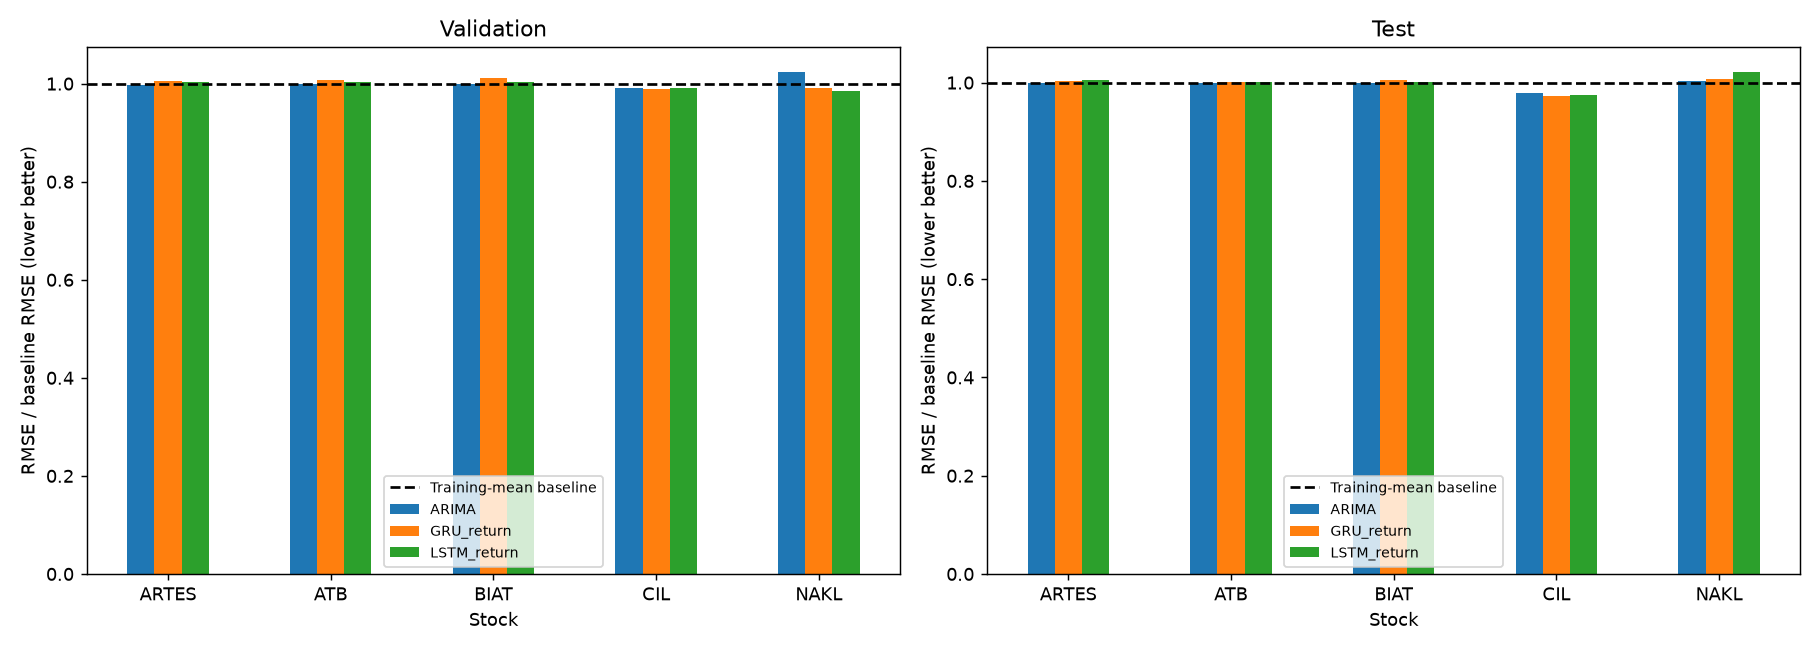

### 01_history

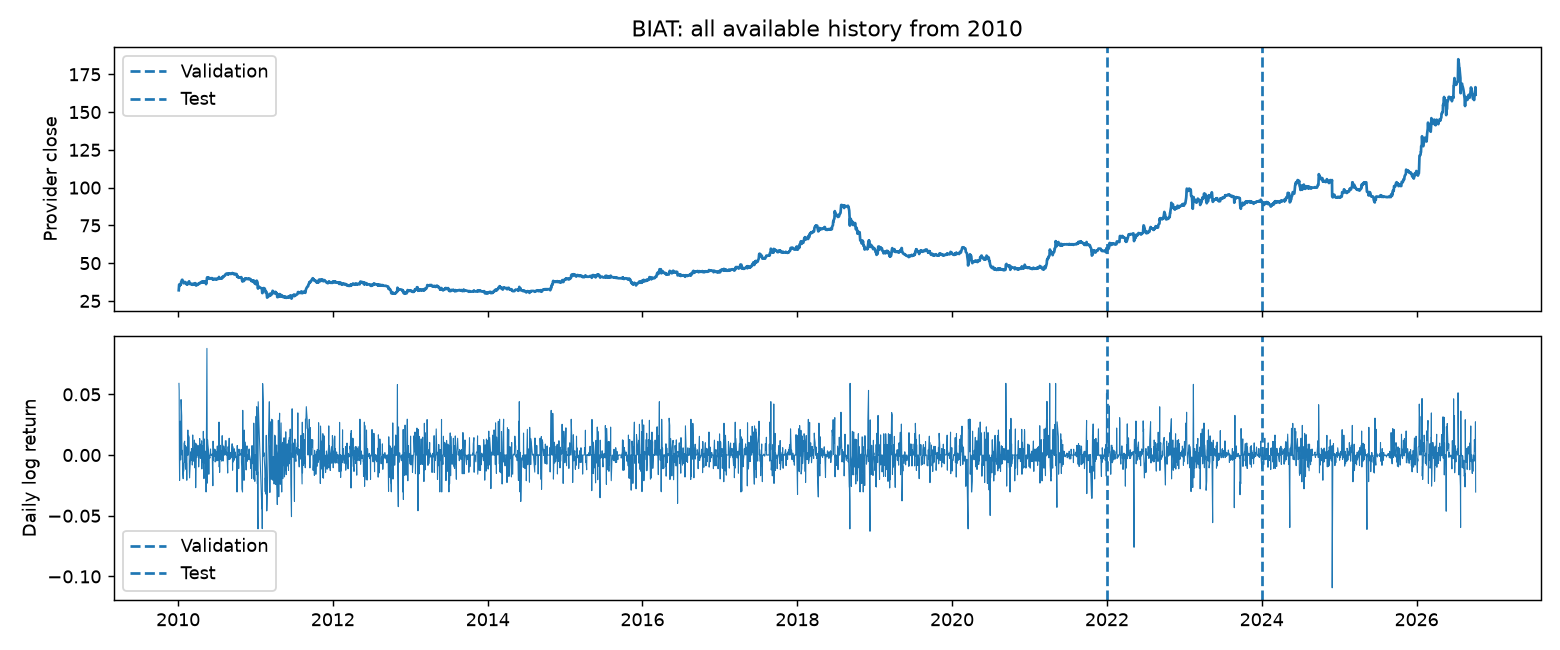

### 02_training

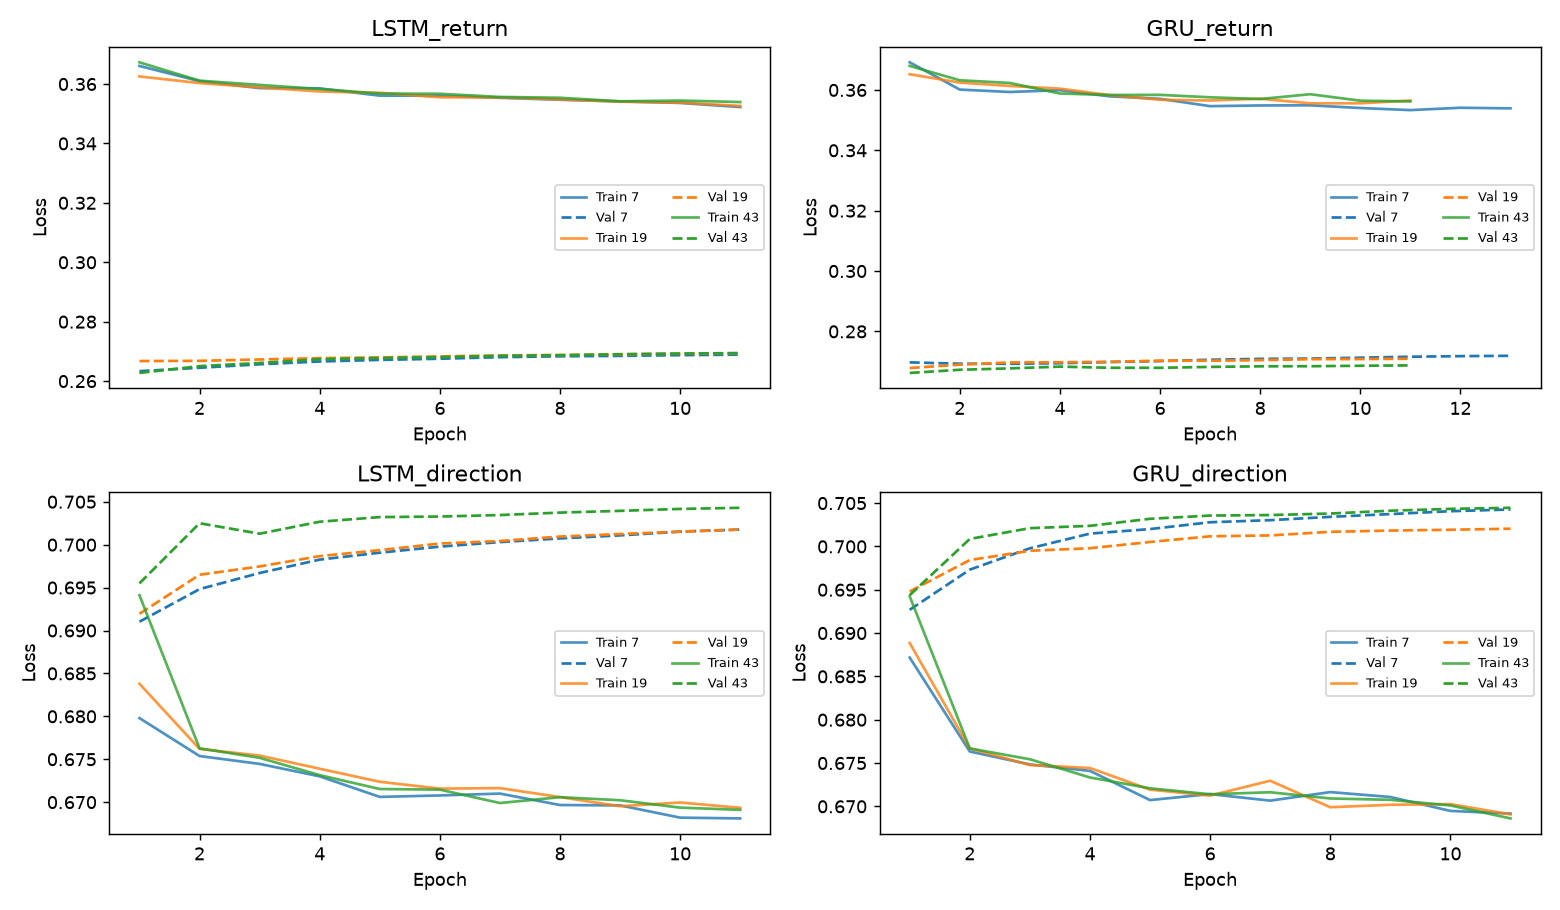

### 03_forecast

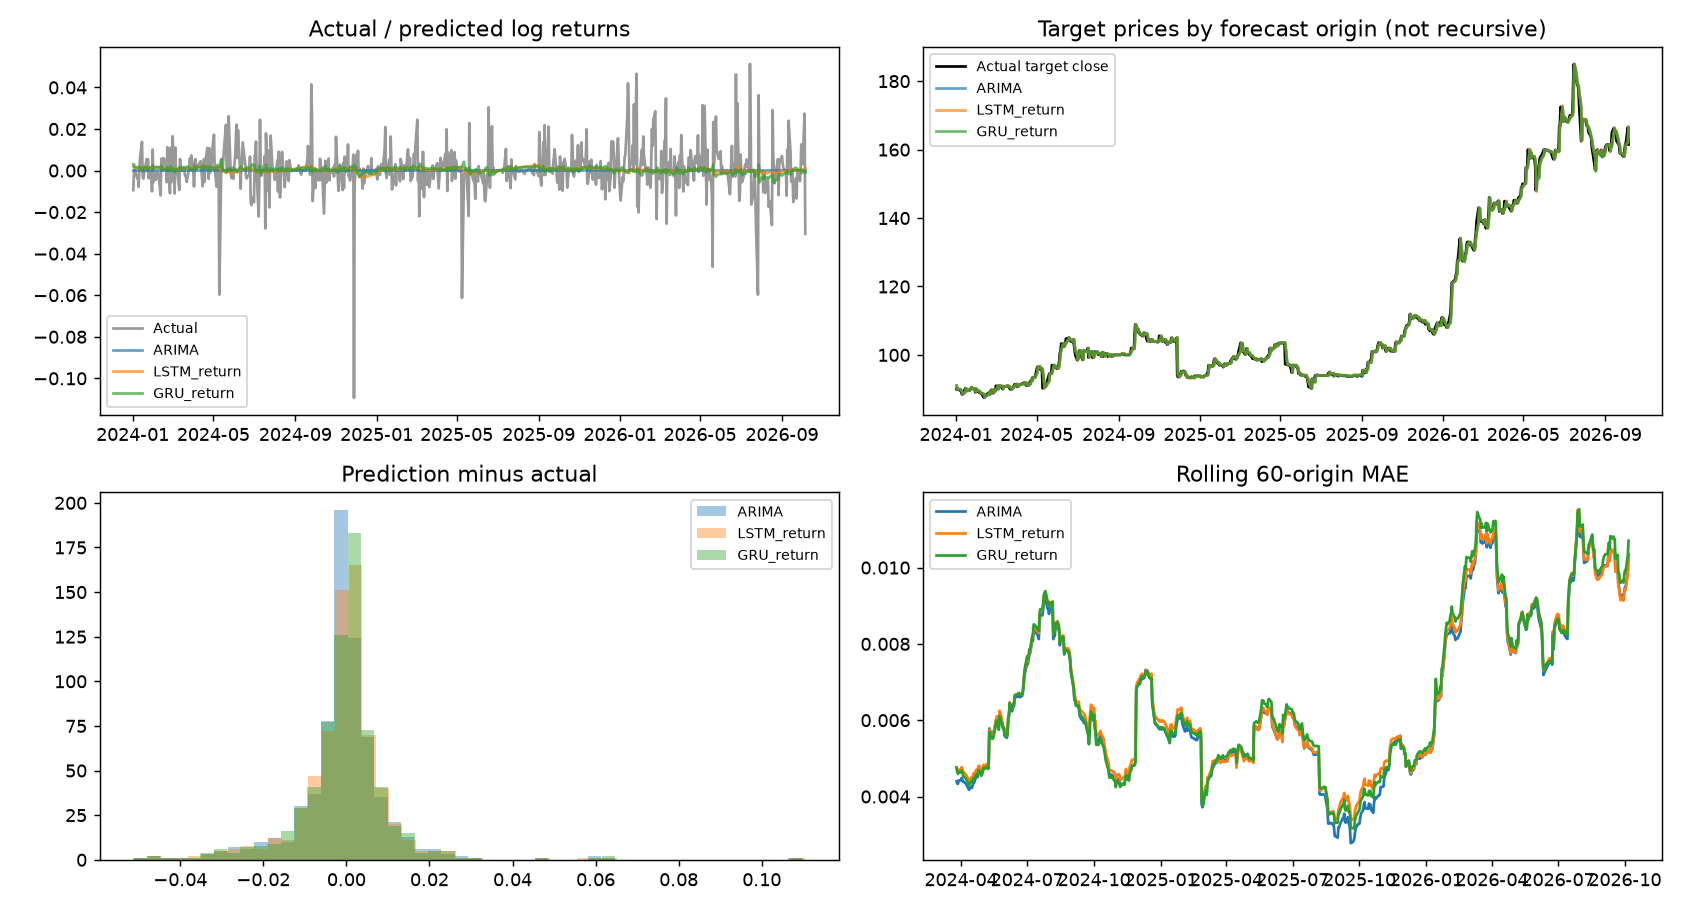

### 04_confusion

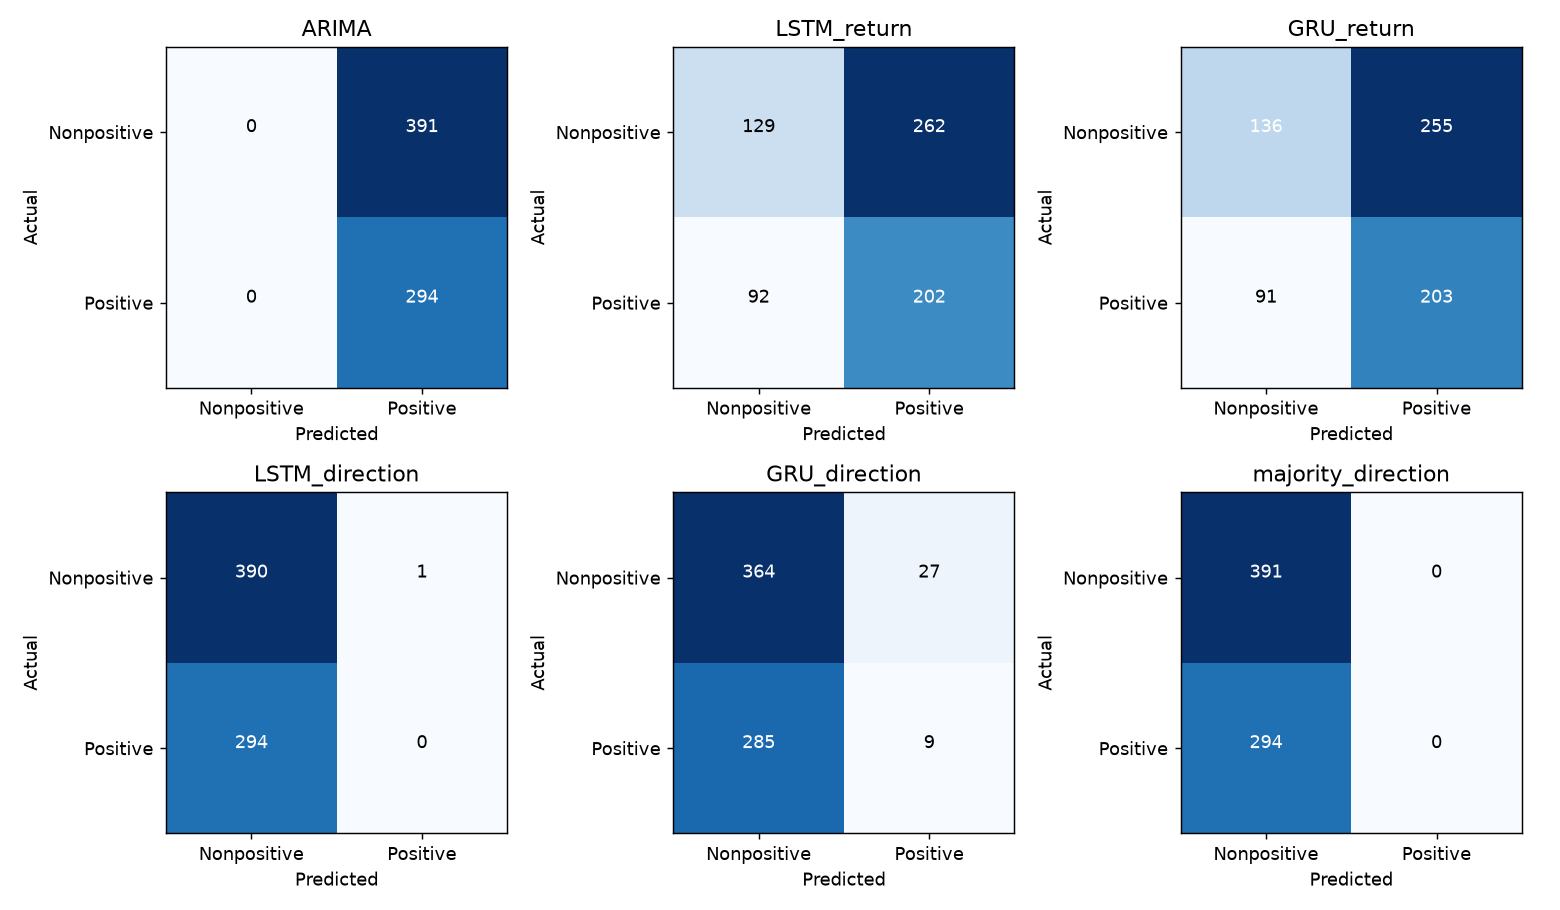

### 05_probability

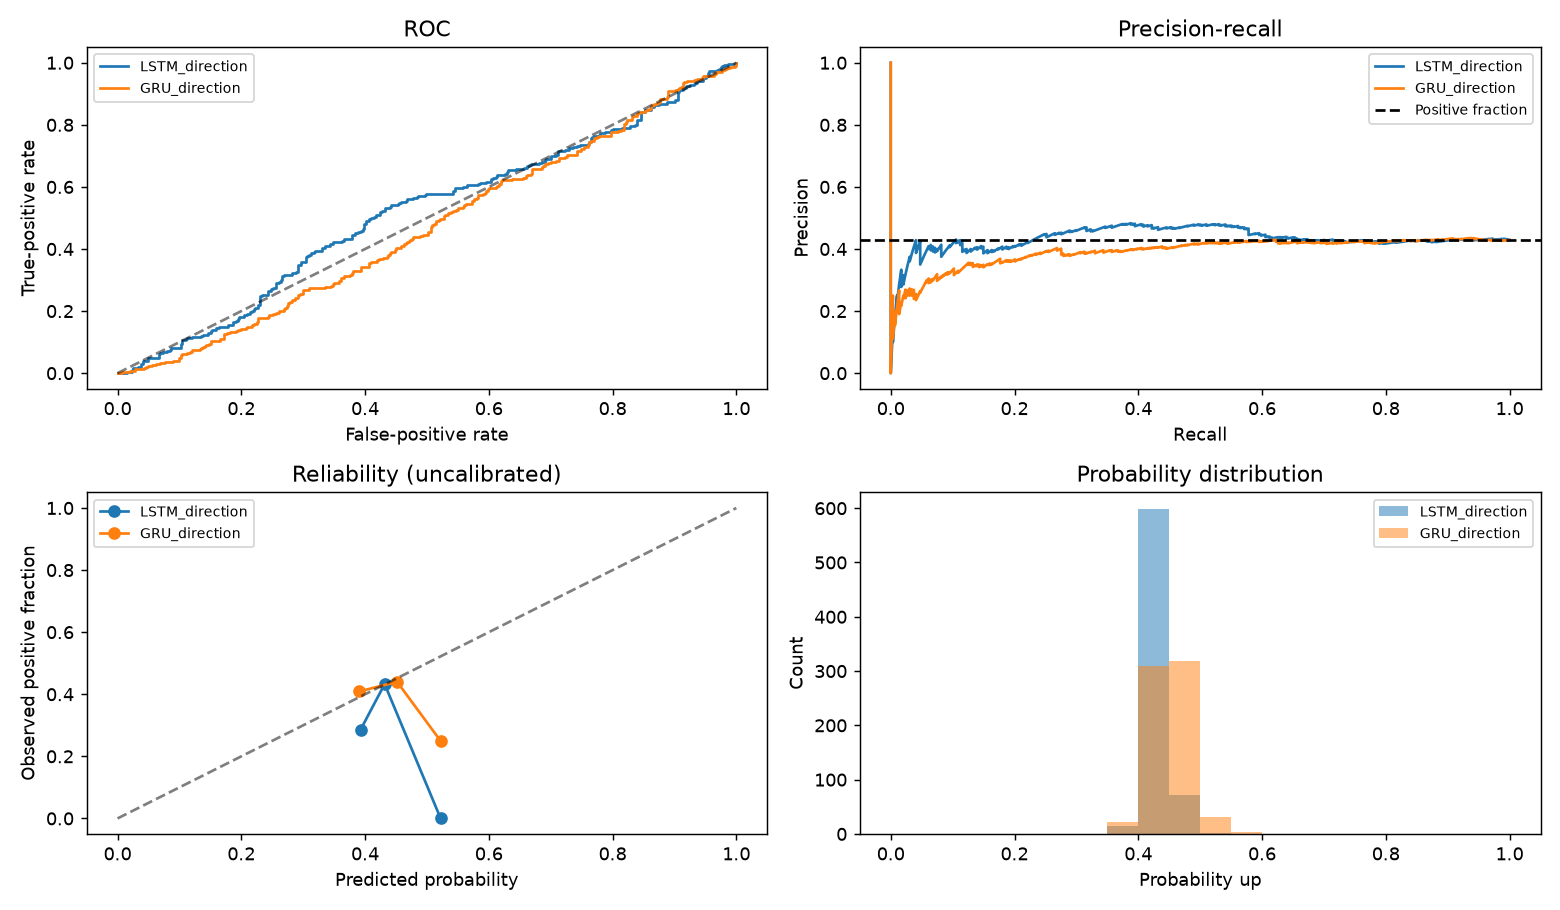

### 06_strategy

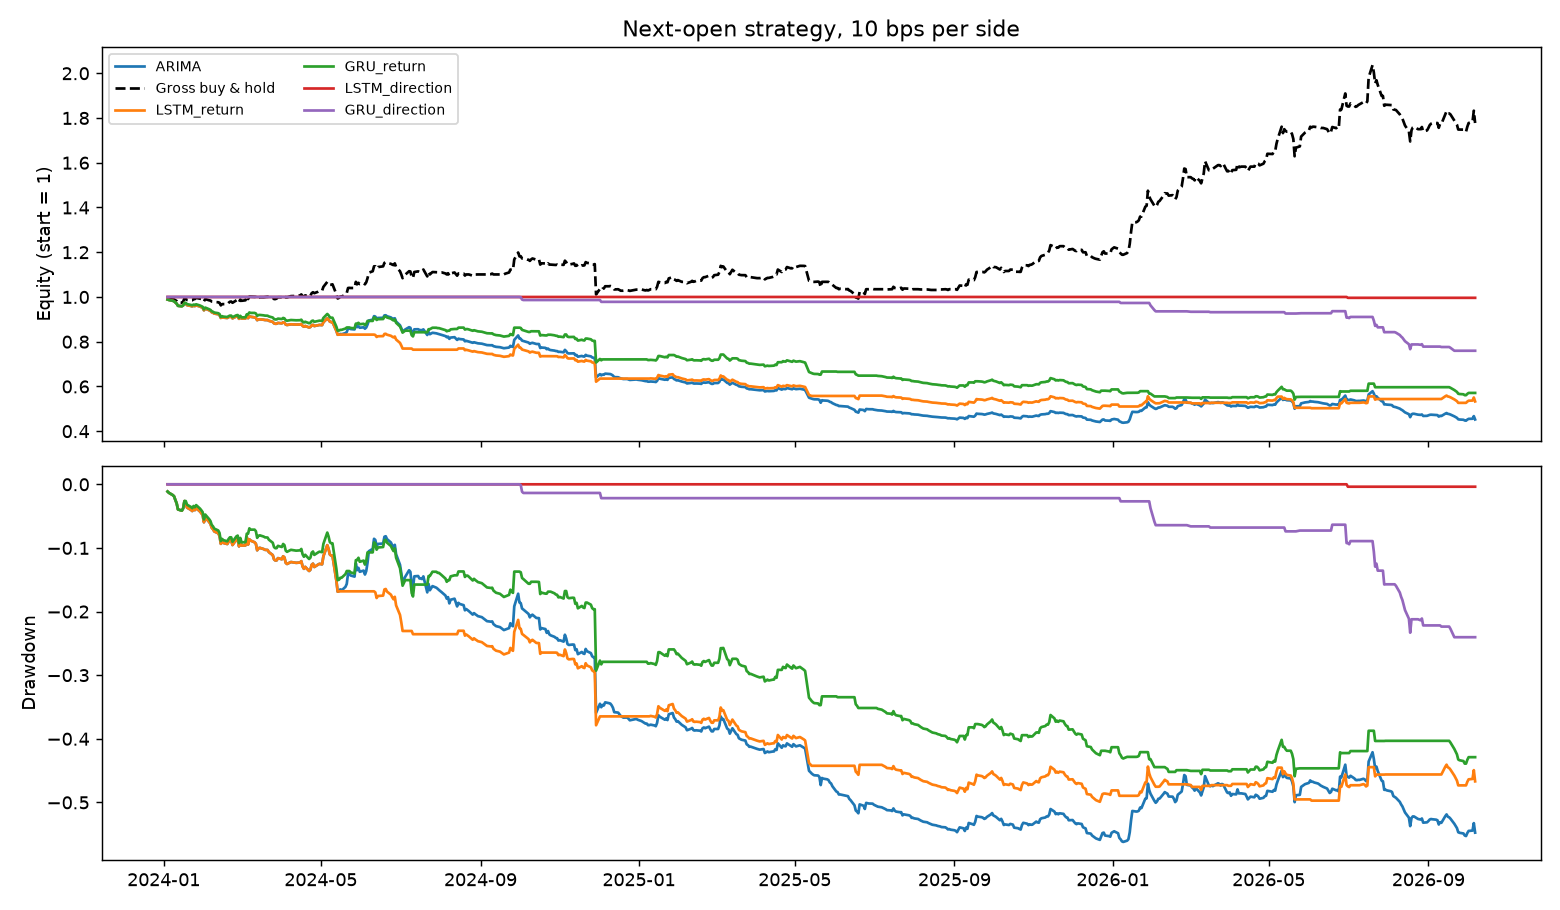

In [8]:
VIEW_STOCK = 'BIAT'
display(Image(filename=str(OUTPUT / 'figures/00_stock_comparison.png')))
for filename in sorted((OUTPUT / 'figures' / VIEW_STOCK).glob('*.png')):
    display(Markdown(f'### {filename.stem}'))
    display(Image(filename=str(filename)))

## 8. Model choice and next step

**Provisional return-model choice: LSTM_return.** The selection rule is the lowest equal-stock mean validation relative RMSE, after averaging seeds within each stock. Direction models are evaluated separately because probability prediction is a different task.

The candidate scores **0.997116** on validation (historical-mean baseline = 1), an error reduction of **0.288%** relative to that baseline. It beats the baseline on **2/5** stocks and has the lowest validation return error on **1/5** stocks.

On test, this candidate scores **1.000522**; the lowest observed test error belongs to **ARIMA** (**0.996132**). Test rankings describe generalization and do not change the validation-based choice. A score above 1 means worse error than the baseline.

This supports a candidate for further validation, not an unconditional production winner. Small average differences and inconsistent stock-level results do not establish a robust advantage; no statistical significance claim is made. Keep ARIMA and the simple baselines as challengers. Before deployment, freeze the candidate settings and evaluate newly collected, unseen observations against those challengers with a predefined acceptance rule. If the candidate does not improve reliably, keep the stronger baseline rather than selecting LSTM because it was preferred.

This run does not deploy, register, or save a serving model. Displayed tables persist in the saved notebook; full in-memory predictions require rerunning after a kernel restart.
